# create_agent와 ReAct 루프

**이 노트북에서 할 일**

1. Ch 20에서 손으로 이은 모델과 도구의 반복 그래프를 함수 `create_agent` 한 줄로 만듭니다.
2. 만든 그래프의 노드·엣지·조건 함수 이름을 출력해, Ch 20 그래프와 같은 점과 다른 점을 찾습니다.
3. 세 질문을 보내 메시지 칸의 응답 수·도구 메시지 수와 호출 ID 짝을 셉니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 5번입니다.
6절에서 2번, 7절에서 1번, 8절에서 2번을 보냈습니다.
모델이 도구를 몇 번 부르느냐에 따라 요청 수가 달라질 수 있습니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 노트북 안 규정 딕셔너리를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.
앞 챕터에서 배운 함수 넷은 도구 파일 `runner_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.
모델 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
langgraph 1.2.11, numpy 2.5.3, python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절을 읽습니다.
자료와 도구를 만들고, 에이전트 그래프를 만들어 모양을 보고, 첫 질문을 보내는 자리입니다.
7~10절은 질문을 바꿔 보내고 Ch 20 그래프와 견주는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch21-create-agent`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 초록 상자 모델 객체 도구 목록 시스템 메시지 글에서 회색 상자 create_agent 한 줄로 화살표가 가고, 거기서 에이전트 그래프 agent CompiledStateGraph 칸으로 화살표가 갑니다. 칸 안에서는 회색 가상 시작점 START에서 회색 상자 모델 노드 model create_agent가 만듦으로 실선이 가고, 모델 노드에서 점선 두 갈래가 나갑니다. 한 갈래는 model_to_tools 요청 있음 라벨을 달고 회색 상자 도구 실행 노드 tools ToolNode로, 다른 갈래는 model_to_tools 요청 없음 라벨을 달고 회색 가상 끝점 END로 갑니다. 도구 실행 노드에서 모델 노드로 tools_to_model 되돌아가는 엣지라는 점선이 올라가는 그림](attachment:01-1-한-줄이-만든-에이전트-그래프.png)

위에서 아래로 읽습니다.
초록 상자는 우리가 넘긴 값 셋이고, 그 아래 회색 상자는 라이브러리가 준 함수 create_agent를 부르는 줄입니다.
칸 안의 회색 상자와 가상 시작점·끝점은 create_agent가 만든 것이고, 노트북 5절 구조 문자열의 상자 넷과 같습니다.
모델 노드에서 나가는 두 갈래와 도구 실행 노드에서 돌아오는 엣지는 모두 조건부 엣지라 점선입니다.
점선 라벨의 이름은 노트북 5절에서 출력한 조건 함수 이름입니다.
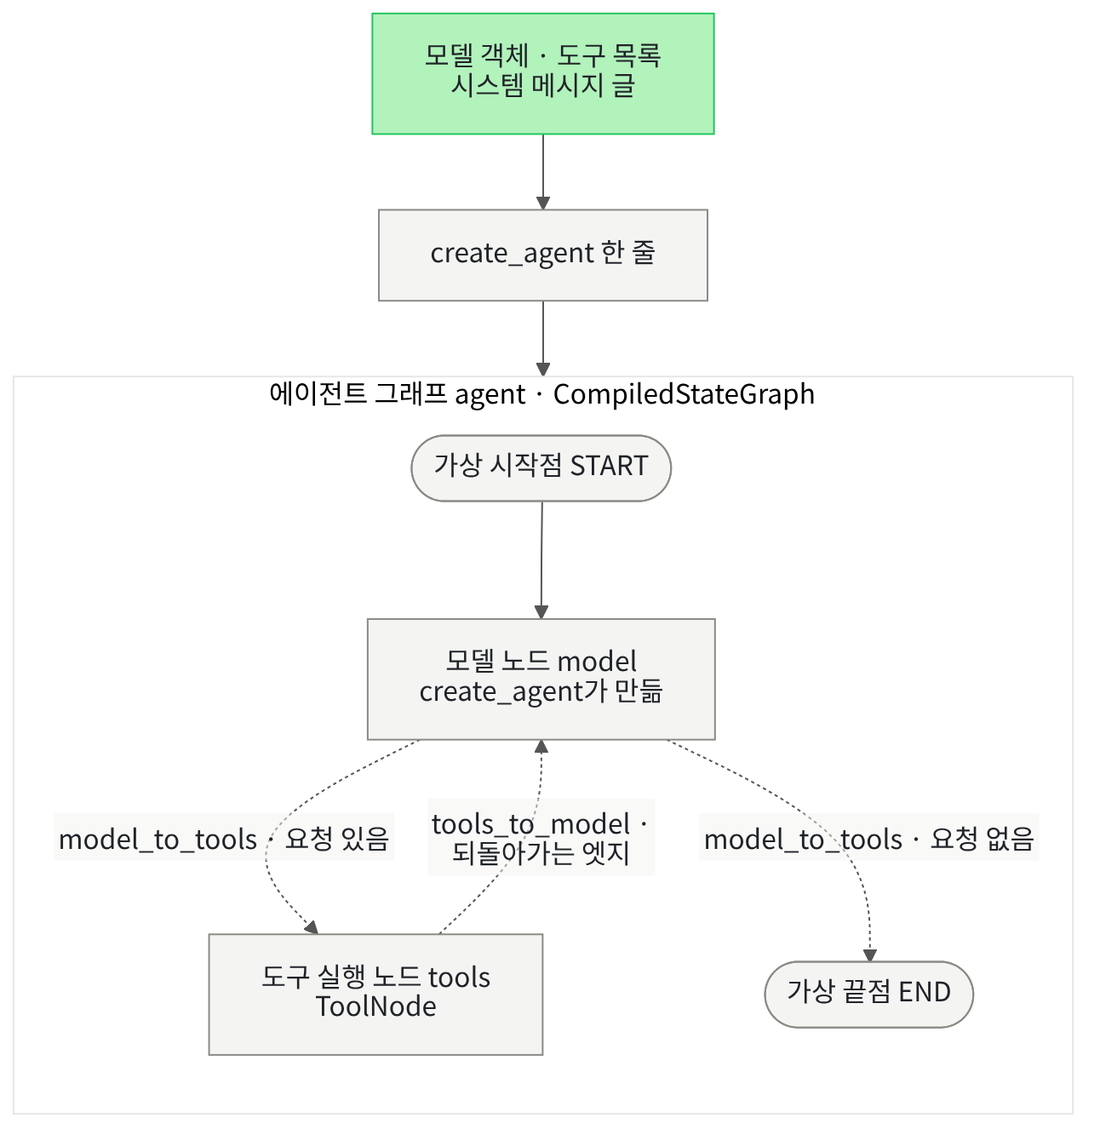

## 1. 준비

Ch 20 01절에서는 모델 노드·도구 실행 노드·도구 조건 함수·되돌아가는 엣지를 하나씩 이어 그래프를 만들었습니다.
이 절에서는 같은 반복을 함수 `create_agent` 한 줄로 만듭니다.
제목의 ReAct는 Ch 7 05절에서 본 말로, 생각과 행동을 번갈아 하는 방식입니다.
모델이 다음 행동을 고르고, 코드가 도구를 실행하고, 그 결과를 다시 모델에게 보여 주는 반복입니다.

첫 셀은 패키지 여섯 개를 설치하고 설치된 판 번호를 출력합니다.
뒤에서 가져오는 도구 파일이 NumPy를 쓰므로, numpy도 함께 설치합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "langgraph==1.2.11" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langgraph: 1.2.11
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `langgraph: 1.2.11`·`numpy: 2.5.3`·`python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모델·메시지·도구 이름은 Ch 19와 Ch 20에서 쓴 이름입니다.
새 이름은 모듈 `langchain.agents`에서 가져오는 함수 `create_agent` 하나입니다.
Ch 20에서 쓴 그래프 이름(`StateGraph`·`ToolNode`·`tools_condition`)은 가져오지 않습니다.

In [2]:
# 에이전트를 만드는 함수 create_agent와, Ch 19에서 쓴 모델·메시지·도구 이름을 가져옵니다
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool

# 앞 챕터에서 배운 함수 넷은 도구 파일에서 가져옵니다
from runner_tools import call_id_lists, estimate_cost, show_messages, sum_usage

print("이 절에서 새로 가져온 이름:", "create_agent")

이 절에서 새로 가져온 이름: create_agent


**결과 읽기** — 출력 줄 `이 절에서 새로 가져온 이름: create_agent`가 보입니다.
모듈 `langchain.agents`는 에이전트를 만드는 도구를 모아 둔 곳입니다.

앞에서 배운 함수는 `runner_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

이 파일은 Ch 20 도구 파일 `graph_tools.py`와 다른 파일입니다.
이 절이 쓰는 함수는 Ch 20 파일에서 본문을 글자 그대로 옮긴 것입니다.
같은 파일에는 뒤 절이 쓰는 함수도 함께 들어 있습니다.
파일 맨 위에서 NumPy를 가져오므로, 첫 셀에서 `numpy`도 설치했습니다.

함수 `show_messages`는 Ch 19 06절, `sum_usage`는 Ch 19 05절에서 배웠습니다.
함수 `estimate_cost`는 Ch 6 06절, `call_id_lists`는 Ch 20 01절에서 배웠습니다.

함수 `show_messages`가 안에서 쓰는 Ch 19 04절 함수 `tool_call_names`도 함께 옮겼습니다.
Ch 20 01절 함수 `run_row`는 옮기지 않았고, 까닭은 10절에서 봅니다.

## 2. 키와 모델 준비

모델은 Ch 20과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.
이 절은 이렇게 만든 모델 객체를 `create_agent`에 넘깁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 도구 호출 요청을 보낼지가 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.

## 3. 규정 자료와 도구

이 챕터는 Ch 20에 이어 교육센터 자료실 규정을 소재로 씁니다.
다음 셀은 Ch 20 01절 셀과 글자까지 같은 코드입니다.
주제어를 키, 규정 글을 값으로 둔 딕셔너리를 만듭니다.

In [5]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
도구는 이 딕셔너리를 읽기만 하므로, Ch 19 06절 말로 읽기 도구입니다.

다음 셀도 Ch 20 01절의 도구 셀과 코드 줄이 같습니다.
셀 안 주석 한 줄만 이 챕터에 맞게 「Ch 20 02절」로 적었습니다.
맨 `@tool` 줄과 독스트링, 매개변수의 `: str` 표시는 Ch 19 01절에서 배운 모양입니다.
딕셔너리에 없는 주제어면 Ch 16 01절처럼 `raise`로 오류를 냅니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(이 오류를 그래프 안에서 다루는 법은 Ch 20 02절에서 보았습니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
독스트링은 도구 설명이 되어 모델 요청에 실립니다.
설명에 주제어 셋을 적어, 모델이 인자에 무엇을 넣을지 알게 했습니다.

## 4. create_agent 한 줄

Ch 20 01절에서는 도구를 모델에게 알려 주고, 상태 형식과 모델 노드를 적었습니다.
그다음 노드 둘을 등록하고 엣지 셋을 이어 컴파일했습니다.
함수 `create_agent`는 이 일을 한 번에 맡아, 컴파일한 그래프를 내놓습니다.
이 절에서는 이 그래프를 에이전트 그래프라고 부릅니다.

넘기는 값은 셋입니다.
첫째 자리에 모델 객체, 인자 `tools`에 도구 목록을 넣습니다.
인자 `system_prompt`에는 시스템 메시지 글을 넣습니다.
시스템 메시지는 Ch 16 03절에서 본, 모델이 따를 규칙을 담은 메시지입니다.
Ch 20의 그래프는 시스템 메시지를 쓰지 않았습니다.

In [7]:
# 모델 객체·도구 목록·시스템 메시지 글을 넘겨 에이전트 그래프를 만듭니다(요청은 아직 보내지 않음)
system_text = "교육센터 자료실 안내 도우미입니다. 자료실 규정을 묻는 질문에는 lookup_policy 도구로 찾은 규정 글에 근거해 답하세요."
agent = create_agent(model, tools=[lookup_policy], system_prompt=system_text)
print("만든 것의 종류:", type(agent).__name__)

만든 것의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`입니다.
Ch 20 01절에서 `builder.compile()`이 내놓은 것과 같은 종류입니다.
이 줄에서는 모델 요청이 나가지 않고, 질문을 넣어 실행할 때 나갑니다.

설치한 langchain 1.4.0 소스로 보면, 이 함수는 안에서 메서드 `bind_tools`로 도구를 모델에게 알려 줍니다.
소스(`factory.py` 995~996행)를 보면, 모델 이름 글자만 넘길 때는 기본 설정으로 모델을 새로 만듭니다.
그래서 이 절은 temperature 0으로 만든 모델 객체를 넘겼습니다.

## 5. 에이전트 그래프의 모양

다음 셀은 Ch 20 01절처럼 그래프가 스스로 그린 구조 문자열을 받아 옵니다.
Ch 20 01절 구조 문자열과 무엇이 같고 무엇이 다른지 봅니다.

In [8]:
# 에이전트 그래프가 스스로 그린 구조 문자열을 받아 옵니다(Ch 13 01절 draw_mermaid)
structure_text = agent.get_graph().draw_mermaid()
print("그래프가 그린 구조:")
print(structure_text)

그래프가 그린 구조:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**결과 읽기** — 라벨 줄 `그래프가 그린 구조:` 아래에서 상자 줄 넷과 화살표 줄 넷을 봅니다.
상자는 `__start__`·`model`·`tools`·`__end__` 넷으로, Ch 20 01절 구조 문자열과 같습니다.
줄 `model -.-> __end__`와 `model -.-> tools`는 조건부 엣지의 두 갈래라 점선입니다.
되돌아가는 엣지 줄 `tools -.-> model`도 점선입니다.
Ch 20 01절 출력에서는 이 줄이 실선 `tools --> model`이었습니다.

구조 문자열의 점선은 조건부 엣지라는 표시입니다.
되돌아가는 엣지가 왜 조건부 엣지인지는 다음 두 셀에서 봅니다.

컴파일한 그래프는 속성 `builder`에 설계 객체를 담아 둡니다.
설계 객체의 속성 `nodes`·`edges`는 Ch 20 01절에서, `branches`는 Ch 20 03절에서 보았습니다.
속성 `channels`에는 상태 칸 이름이 들어 있습니다.

In [9]:
# 설계 객체에서 등록된 노드, 엣지 수, 상태 칸, 노드 tools의 종류를 봅니다
agent_builder = agent.builder
print("등록된 노드:", list(agent_builder.nodes))
print("고정 엣지로 적힌 수:", len(agent_builder.edges))
print("조건부 엣지를 적은 노드 수:", len(agent_builder.branches))
print("상태 칸:", list(agent_builder.channels))
# 노드마다 속성 runnable에 실제로 실행할 것이 들어 있습니다
tools_node = agent_builder.nodes["tools"].runnable
print("노드 tools의 종류:", type(tools_node).__name__)

등록된 노드: ['model', 'tools']
고정 엣지로 적힌 수: 1
조건부 엣지를 적은 노드 수: 2
상태 칸: ['messages', 'jump_to', 'structured_response']
노드 tools의 종류: ToolNode


**결과 읽기** — 출력 줄 `등록된 노드: ['model', 'tools']`로, 노드 이름은 Ch 20 01절과 같습니다.
출력 줄 `고정 엣지로 적힌 수: 1`은 시작 엣지 하나이고, Ch 20 01절은 되돌아가는 엣지까지 둘이었습니다.
출력 줄 `조건부 엣지를 적은 노드 수: 2`로, 모델 노드와 도구 실행 노드 모두에 조건부 엣지가 있습니다.
출력 줄 `상태 칸: ['messages', 'jump_to', 'structured_response']`는 Ch 20 01절 상태와 다릅니다.
출력 줄 `노드 tools의 종류: ToolNode`로, 도구 실행 노드는 Ch 20과 같은 종류입니다.

Ch 20 01절 상태 형식의 칸은 메시지 칸 `messages`와 실행 흔적 칸 `trace` 둘이었습니다.
에이전트 그래프에는 실행 흔적 칸이 없어, 흔적 칸 길이로 모델 요청을 셀 수 없습니다.
설치판 소스로 보면 칸 `jump_to`는 라이브러리가 그래프 안에서만 쓰는 칸입니다.
칸 `structured_response`는 02절 구조화 출력에서 봅니다.

속성 `branches`는 조건부 엣지를 적은 노드마다, 조건 함수 이름을 키로 한 딕셔너리를 담습니다.
그 딕셔너리 값의 속성 `ends`는 이름표와 갈 곳을 이은 딕셔너리로, Ch 13 03절 이름표 표와 같은 모양입니다.
다음 셀은 조건 함수 이름과 갈 수 있는 곳을 출력합니다.

In [10]:
# 조건부 엣지마다 조건 함수의 이름과 갈 수 있는 곳을 봅니다
for source in agent_builder.branches:
    specs = agent_builder.branches[source]
    for name in specs:
        # 속성 ends는 이름표와 갈 곳을 이은 딕셔너리라, 값만 모으면 갈 수 있는 곳입니다
        ends = list(specs[name].ends.values())
        print(source, "| 조건 함수:", name, "| 갈 수 있는 곳:", ends)

tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__']


**결과 읽기** — 출력 줄 `tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']`이 먼저 나옵니다.
출력 줄 `model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__']`이 다음입니다.
모델 노드 뒤 조건 함수의 이름은 `model_to_tools`이고, Ch 20의 도구 조건 함수 `tools_condition`이 아닙니다.
도구 실행 노드 뒤에도 조건 함수 `tools_to_model`이 붙어, 되돌아가는 엣지가 점선으로 그려졌습니다.
이 조건 함수가 갈 수 있는 곳은 `model` 하나라, 이 에이전트 그래프에서는 늘 모델 노드로 돌아갑니다.

설치한 langchain 1.4.0 소스(`factory.py` 28행)도 `ToolNode`만 가져오고 `tools_condition`은 가져오지 않습니다.
소스로 보면 조건 함수 `model_to_tools`는 마지막 응답에 도구 호출 요청이 없으면 끝으로 보냅니다.
요청이 있으면 요청마다 도구 실행 노드를 따로 부릅니다(소스 1923~1975행).

소스(2004~2037행)를 보면 조건 함수 `tools_to_model`이 끝으로 가는 경우는 둘뿐입니다.
도구를 부르자마자 끝내는 설정의 도구와, 02절에서 보는 구조화 출력용 도구가 있을 때입니다.
이 두 경우는 이번에 실행하지 않았습니다.

## 6. 도구가 필요한 질문

첫 질문은 Ch 20 01절 7절과 같은 대출 질문입니다.
입력 상태에는 메시지 칸에 질문 하나만 넣습니다.
실행 흔적 칸이 없으므로, Ch 20처럼 빈 흔적 목록을 넣지 않습니다.

실행 전에 예상해 봅니다.
모델이 대출 규정을 찾는 요청을 보내면, 모델 노드 → 도구 실행 노드 → 모델 노드 차례로 지날 것입니다.

In [11]:
# 규정을 찾아야 답할 수 있는 질문으로 에이전트 그래프를 실행합니다(모델 노드를 지날 때마다 모델 요청 1번)
loan_question = "자료실에서 일반 도서를 며칠 빌릴 수 있나요?"
loan_state = {"messages": [HumanMessage(content=loan_question)]}
loan_result = agent.invoke(loan_state)
result_keys = list(loan_result.keys())
print("결과 딕셔너리의 키:", result_keys)
print("메시지 칸의 메시지 수:", len(loan_result["messages"]))

결과 딕셔너리의 키: ['messages']
메시지 칸의 메시지 수: 4


**결과 읽기** — 출력 줄 `결과 딕셔너리의 키: ['messages']`로, 결과에는 메시지 칸 하나만 나왔습니다.
출력 줄 `메시지 칸의 메시지 수: 4`입니다.
질문 하나에 메시지 셋이 더해졌습니다.

설치판 소스로 보면 칸 `jump_to`는 결과에서 빠지게 적혀 있습니다.
구조화 출력을 쓰지 않아, 칸 `structured_response`에는 값이 생기지 않았습니다.

다음 셀은 Ch 19 06절 함수 `show_messages`로 메시지 칸을 차례로 출력합니다.

In [12]:
# 메시지 칸을 차례로 출력합니다(Ch 19 06절 함수 show_messages)
print("메시지 칸:")
show_messages(loan_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래 네 줄이 메시지 칸의 차례입니다.
질문 다음 줄은 `AIMessage | 도구 호출 요청: ['lookup_policy']`입니다.
셋째 줄 도구 메시지는 결과 상태가 `success`이고, 내용은 대출 규정 글입니다.
넷째 줄 `AIMessage | 도구 호출 요청: []`는 요청이 없는 응답이라, 조건 함수가 끝으로 보냈습니다.
모델을 부르고, 모델이 요청한 도구를 실행하고, 다시 모델을 부른 흐름입니다.

Ch 20 01절 7절 메시지 네 줄과 종류·차례가 같습니다.

4절에서 넘긴 시스템 메시지가 메시지 칸에 들어갔는지 봅니다.
Ch 16 03절에서는 시스템 메시지가 대화 기록의 첫 메시지였습니다.
다음 셀은 메시지 칸의 종류 이름을 모아 셉니다.

In [13]:
# 메시지 칸의 종류 이름을 모아, 시스템 메시지가 들어 있는지 셉니다
kinds = []
for message in loan_result["messages"]:
    kinds.append(type(message).__name__)
print("메시지 종류:", kinds)
print("시스템 메시지 수:", kinds.count("SystemMessage"))

메시지 종류: ['HumanMessage', 'AIMessage', 'ToolMessage', 'AIMessage']
시스템 메시지 수: 0


**결과 읽기** — 출력 줄 `메시지 종류: ['HumanMessage', 'AIMessage', 'ToolMessage', 'AIMessage']`입니다.
출력 줄 `시스템 메시지 수: 0`으로, 시스템 메시지는 메시지 칸에 남지 않았습니다.

설치판 소스(`factory.py` 1451~1452행)로 보면, 모델 노드는 요청마다 시스템 메시지를 메시지 앞에 붙여 보냅니다.
요청에 실린 모습은 이번 출력으로는 보이지 않습니다.

다음 셀은 첫 응답에 담긴 도구 호출 요청의 이름과 인자를 봅니다.

In [14]:
# 둘째 메시지(첫 응답)에 담긴 도구 호출 요청의 이름과 인자를 봅니다
first_response = loan_result["messages"][1]
for call in first_response.tool_calls:
    print("도구 이름:", call["name"], "| 인자:", call["args"])

도구 이름: lookup_policy | 인자: {'topic': '대출'}


**결과 읽기** — 출력 줄 `도구 이름: lookup_policy | 인자: {'topic': '대출'}`입니다.
모델이 질문을 읽고 주제어 `대출`을 골라 인자에 넣었습니다.
도구를 부를지와 인자는 모델이 정했고, 도구를 실행한 것은 도구 실행 노드입니다.

다음 셀은 도구 파일 함수 `call_id_lists`로 요청 id 목록과 호출 ID 목록을 모아, 짝이 맞는지 봅니다.
이 목록은 도구 실행 노드가 옮겨 적는 값이라, 모델이 요청을 몇 건 보내든 짝이 맞아야 합니다.
그래서 셀 끝에서 `assert`로 확인합니다.

In [15]:
# 대출 질문 흐름에서 요청 id 목록과 호출 ID 목록이 같은 차례로 짝이 맞는지 봅니다
loan_ids = call_id_lists(loan_result["messages"])
print("요청 id 수:", len(loan_ids["요청 id"]))
print("호출 ID 수:", len(loan_ids["호출 ID"]))
print("짝이 맞는가:", loan_ids["요청 id"] == loan_ids["호출 ID"])
# 도구 실행 노드가 옮겨 적는 값이라 매번 같아야 합니다
assert loan_ids["요청 id"] == loan_ids["호출 ID"], "도구 메시지마다 같은 차례의 요청 id가 옮겨져야 합니다"

요청 id 수: 1
호출 ID 수: 1
짝이 맞는가: True


**결과 읽기** — 출력 줄 `요청 id 수: 1`과 `호출 ID 수: 1`입니다.
출력 줄 `짝이 맞는가: True`로, 도구 실행 노드가 요청 `id`를 도구 메시지에 옮겨 적었습니다.
칸 `id`의 값은 요청마다 새로 붙어 실행마다 다르므로, 여기에 옮겨 적지 않습니다.

다음 셀은 메시지 칸의 마지막 응답을 봅니다.

In [16]:
# 메시지 칸의 마지막 응답을 봅니다(도구 호출 요청 수와 답 글)
last_message = loan_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(last_message.tool_calls))
print("답 글:")
print(last_message.content)

마지막 응답의 도구 호출 요청 수: 0
답 글:
일반 도서는 **1인 5권까지, 14일 동안** 빌릴 수 있습니다.


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
라벨 줄 `답 글:` 아래가 모델이 도구 메시지를 읽고 쓴 최종 답입니다.

답 글의 문장은 실행마다 달라질 수 있어, 결론에 쓰지 않습니다.
이번 실행에서는 답 글에 도구 메시지의 `1인 5권까지`와 `14일`이 들어 있었습니다.
답 글의 별표 두 개(`**`)는 모델이 굵은 글씨를 표시하려고 붙인 기호입니다.

## 7. 도구가 필요 없는 질문

둘째 질문은 Ch 20 01절 8절과 같은 인사입니다.
같은 에이전트 그래프에 질문만 바꿔 넣습니다.
실행 전에 예상해 봅니다.
모델이 도구 호출 요청 없이 바로 답하면, 모델 노드를 한 번만 지나고 끝날 것입니다.

In [17]:
# 규정을 찾을 까닭이 없는 인사 질문으로 같은 에이전트 그래프를 실행합니다(모델 요청 1번 예상)
greet_question = "안녕하세요. 한 문장으로 인사해 주세요."
greet_state = {"messages": [HumanMessage(content=greet_question)]}
greet_result = agent.invoke(greet_state)
print("메시지 칸:")
show_messages(greet_result["messages"])
print("답 글:", greet_result["messages"][-1].content)

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: []
답 글: 안녕하세요, 무엇을 도와드릴까요?


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래는 `HumanMessage`와 `AIMessage | 도구 호출 요청: []` 두 줄입니다.
첫 응답에 요청이 없어, 조건 함수 `model_to_tools`가 바로 끝으로 보냈습니다.
도구 실행 노드는 한 번도 실행되지 않았고, 모델 요청은 1번입니다.

답 글은 실행마다 달라질 수 있습니다.
이번 실행에서는 `안녕하세요, 무엇을 도와드릴까요?`였습니다.
노트북 밖에서 이 질문을 다섯 번 보냈을 때도 다섯 번 모두 도구 호출 요청이 없었습니다.

## 8. 값 바꿔 보기 · 규정 두 가지를 묻는 질문

바꿀 값은 질문 하나입니다.
운영 시간과 연체 규정을 함께 묻는, Ch 20 01절 9절과 같은 질문으로 바꿉니다.
Ch 20에서는 `bind_tools(tools, parallel_tool_calls=False)`로 한 응답에 요청을 하나까지만 받았습니다.
함수 `create_agent`에는 이 값을 넣는 인자가 없습니다.
설치판 소스(`factory.py` 1431~1436행)도 이 값 없이 도구를 알려 줍니다.

langchain-openai 1.6.0 소스 설명으로는, 이 값을 보내지 않으면 여럿 담기가 켜진 채로 요청됩니다.
실행 전에 예상해 봅니다.
한 응답에 요청 둘이 함께 오면, 모델 요청은 Ch 20의 3번보다 적은 2번일 것입니다.

In [18]:
# 바꿀 값: 질문 하나만, 규정 두 가지가 필요한 질문으로 바꿔 같은 에이전트 그래프를 실행합니다
two_question = "자료실 운영 시간과 연체 규정을 함께 알려 주세요."
two_state = {"messages": [HumanMessage(content=two_question)]}
two_result = agent.invoke(two_state)
print("메시지 칸:")
show_messages(two_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy', 'lookup_policy']
ToolMessage | 결과 상태: success | 내용: 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.
ToolMessage | 결과 상태: success | 내용: 연체한 일수만큼 새 대출이 제한됩니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래 다섯 줄입니다.
둘째 줄은 `AIMessage | 도구 호출 요청: ['lookup_policy', 'lookup_policy']`로, 한 응답에 요청 둘이 들었습니다.
그 뒤에 도구 메시지 둘이 이어지고, 둘 다 결과 상태가 `success`입니다.
마지막 줄 `AIMessage | 도구 호출 요청: []`가 최종 답입니다.

다음 셀은 응답마다 도구 호출 요청 수와 인자를 보고, 호출 ID 짝을 셉니다.
Ch 20 01절 9절과 같은 코드입니다.

In [19]:
# 응답마다 도구 호출 요청 수와 인자를 차례로 보고, 호출 ID 짝을 셉니다
for message in two_result["messages"]:
    if type(message).__name__ == "AIMessage":
        print("응답 | 도구 호출 요청 수:", len(message.tool_calls))
        for call in message.tool_calls:
            print("  인자:", call["args"])
two_ids = call_id_lists(two_result["messages"])
print("호출 ID 짝이 맞는가:", two_ids["요청 id"] == two_ids["호출 ID"])

응답 | 도구 호출 요청 수: 2
  인자: {'topic': '운영'}
  인자: {'topic': '연체'}
응답 | 도구 호출 요청 수: 0
호출 ID 짝이 맞는가: True


**결과 읽기** — 첫 응답은 `응답 | 도구 호출 요청 수: 2`이고, 인자는 `{'topic': '운영'}`과 `{'topic': '연체'}`입니다.
둘째 응답은 `응답 | 도구 호출 요청 수: 0`이라 최종 답입니다.
출력 줄 `호출 ID 짝이 맞는가: True`로, 두 도구 메시지 모두 짝이 맞았습니다.

Ch 20 01절 9절에서는 요청이 응답마다 한 건씩 와서 모델 요청이 3번이었습니다.
여기서는 한 응답에 두 건이 함께 와서 모델 요청이 2번입니다.
설치판 소스로 보면 조건 함수 `model_to_tools`는 Ch 13 05절의 `Send`로 요청마다 도구 실행 노드를 따로 부릅니다.
두 도구 실행이 한 단계 안에서 함께 도는지는 이번에 세지 않았습니다.

## 9. 사용량과 예상 비용

다음 셀은 Ch 19 05절 함수 `sum_usage`로 대출 질문 흐름의 요청 수와 토큰을 더합니다.
함수가 세는 요청 수는 메시지 칸의 응답(`AIMessage`) 수입니다.
모델 노드가 한 번 돌 때마다 응답이 하나 붙으므로, 이 수가 곧 모델 요청 수입니다.

In [20]:
# 대출 질문 흐름의 응답 둘에서 요청 수와 입력·출력 토큰을 더합니다(Ch 19 05절 함수 sum_usage)
loan_usage = sum_usage(loan_result["messages"])
print("대출 질문 사용량:", loan_usage)

대출 질문 사용량: {'requests': 2, 'input_tokens': 456, 'output_tokens': 44}


**결과 읽기** — 라벨 `대출 질문 사용량:` 뒤 딕셔너리에서 `'requests': 2`는 응답 둘, 곧 모델 요청 2번입니다.
입력 토큰은 `'input_tokens': 456`으로, 두 요청의 입력을 더한 값입니다.
설치판 소스로 보면 요청마다 시스템 메시지와 도구 명세가 함께 실립니다.

출력 토큰은 실행마다 달라질 수 있습니다.
이번 실행에서는 `'output_tokens': 44`였습니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 이 사용량의 예상 비용을 셉니다.
요금은 2026-09-17 요금표의 100만 토큰당 달러입니다.

In [21]:
# 2026-09-17 요금표(100만 토큰당 달러)로 대출 질문 흐름의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
loan_cost = estimate_cost(loan_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(loan_cost, 6)
print("대출 질문 예상 비용(달러):", rounded_cost)

대출 질문 예상 비용(달러): 0.00054


**결과 읽기** — 라벨 `대출 질문 예상 비용(달러):` 뒤 값이 요금표로 어림한 예상 비용이고, 청구 금액이 아닙니다.
사용량에 캐시 입력 칸이 없어, 입력 토큰은 모두 입력 요금으로 셌습니다.

출력 토큰이 실행마다 달라질 수 있어, 이 값도 달라질 수 있습니다.
이번 실행에서는 `0.00054`달러였습니다.

## 10. Ch 20 그래프와 견주기

Ch 20 01절 함수 `run_row`는 실행 흔적 칸의 길이로 모델 요청 수를 셌습니다.
에이전트 그래프의 결과에는 흔적 칸이 없어, 그 함수를 그대로 쓸 수 없습니다.
다음 셀은 응답 수로 모델 요청 수를 세는 함수를 새로 만듭니다.

In [22]:
# 실행 결과 하나를 기록 한 줄로 만듭니다(모델 요청 수 = 응답 메시지 수)
def agent_row(question_name, result):
    ids = call_id_lists(result["messages"])
    usage = sum_usage(result["messages"])
    row = {"질문": question_name}
    row["모델 요청 수"] = usage["requests"]
    row["도구 메시지 수"] = len(ids["호출 ID"])
    row["호출 ID 짝"] = ids["요청 id"] == ids["호출 ID"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `agent_row`는 칸 넷을 담은 딕셔너리를 내놓습니다.
칸은 질문·모델 요청 수·도구 메시지 수·호출 ID 짝입니다.
모델 요청 수는 함수 `sum_usage`가 센 응답 수입니다.

다음 셀은 세 질문의 기록을 모아 한 줄씩 출력합니다.

In [23]:
# 세 질문의 기록을 모아 라벨 줄 아래에 한 줄씩 출력합니다
agent_rows = []
agent_rows.append(agent_row("대출 질문", loan_result))
agent_rows.append(agent_row("인사 질문", greet_result))
agent_rows.append(agent_row("운영·연체 질문", two_result))
print("질문 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝")
for row in agent_rows:
    print(row["질문"], "|", row["모델 요청 수"], "|", row["도구 메시지 수"], "|", row["호출 ID 짝"])

질문 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝
대출 질문 | 2 | 1 | True
인사 질문 | 1 | 0 | True
운영·연체 질문 | 2 | 2 | True


**결과 읽기** — 라벨 줄 아래 세 줄입니다.
대출 질문은 `대출 질문 | 2 | 1 | True`입니다.
인사 질문은 `인사 질문 | 1 | 0 | True`입니다.
바꾼 질문은 `운영·연체 질문 | 2 | 2 | True`입니다.

Ch 20 01절 10절 표에서 모델 요청은 2·1·3번, 도구 메시지는 1·0·2개였습니다.
대출·인사 질문은 같고, 운영·연체 질문만 모델 요청이 하나 적습니다.
한 응답에 요청 둘이 함께 왔기 때문입니다.
그래서 「모델 요청 수 = 도구 메시지 수 + 1」은 요청을 하나씩 받을 때만 맞는 셈입니다.
세 질문 모두 호출 ID 짝은 맞았습니다.

Ch 20 01절에서 손으로 이은 부품이 에이전트 그래프에서 맡는 곳은 아래와 같습니다.

- 도구를 모델에게 알려 주는 `bind_tools`는 `create_agent`가 안에서 부르고, 여럿 담기 값은 넣지 않습니다.
- 메시지 칸과 실행 흔적 칸을 둔 상태 형식은, 칸 `messages`·`jump_to`·`structured_response`인 상태로 바뀝니다.
- 우리가 적은 모델 노드 `call_model`은, `create_agent`가 만든 이름 `model`인 노드가 맡습니다.
- 도구 실행 노드 `ToolNode(tools)`는 이름도 종류도 같은 노드 `tools`가 맡습니다.
- 도구 조건 함수 `tools_condition`은 조건 함수 `model_to_tools`가 맡습니다.
- 실선이던 되돌아가는 엣지 `add_edge("tools", "model")`는 조건 함수 `tools_to_model`의 점선이 맡습니다.

## 정리

1. 함수 `create_agent` 한 줄로 만든 에이전트 그래프에도 노드 `model`·`tools`와 상자 넷이 있었습니다.
2. 갈래는 조건 함수 `model_to_tools`·`tools_to_model`이 맡아, 되돌아가는 엣지도 점선이었습니다.
3. 대출·인사·운영과 연체 질문의 모델 요청은 2·1·2번, 도구 메시지는 1·0·2개였습니다.

02절에서는 `create_agent`가 답을 정해 둔 양식으로 내놓게 하는 구조화 출력 두 가지를 봅니다.